In [495]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [496]:
import  pandas  as pd
pd.set_option('display.max_columns', None)
url = "/content/drive/MyDrive/Colab Notebooks/bigdata/"
df = pd.read_csv(url+"hotel_bookings.csv")
df.sample(5)

,hotel,lead_time,arrival_month,adults,children,babies,country,market_segment,deposit_type,customer_type,adr,previous_cancellations,special_requests,is_canceled
318,Resort Hotel,125,Aug,2,2.0,0,GBR,Online,No Deposit,Group,158.0,1,4,1
382,City Hotel,81,Jul,2,0.0,0,GBR,Online,Refundable,Group,276.0,3,2,1
75,City Hotel,214,Sep,1,1.0,0,JPN,Corporate,Refundable,Group,74.0,1,0,1
202,Resort Hotel,241,Jun,3,0.0,0,GBR,Offline,Refundable,Transient,159.0,3,3,1
49,City Hotel,150,Mar,2,0.0,0,JPN,Corporate,No Deposit,Transient,76.0,4,2,1


In [497]:
df.describe()

,lead_time,adults,children,babies,adr,previous_cancellations,special_requests,is_canceled
count,457.000000,457.000000,449.000000,457.000000,452.000000,457.000000,457.000000,457.000000
mean,181.516411,2.317287,0.389755,0.045952,229.280973,2.595186,2.048140,0.660832
std,131.235593,1.364488,0.669476,0.209610,270.274359,1.679409,1.385182,0.473946
min,0.000000,1.000000,0.000000,0.000000,-50.000000,0.000000,0.000000,0.000000
25%,95.000000,2.000000,0.000000,0.000000,143.000000,1.000000,1.000000,0.000000
50%,176.000000,2.000000,0.000000,0.000000,225.000000,3.000000,2.000000,1.000000
75%,258.000000,3.000000,1.000000,0.000000,281.250000,4.000000,3.000000,1.000000
max,1500.000000,20.000000,2.000000,1.000000,5000.000000,5.000000,4.000000,1.000000


In [498]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 457 entries, 0 to 456
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   hotel                   457 non-null    object 
 1   lead_time               457 non-null    int64  
 2   arrival_month           457 non-null    object 
 3   adults                  457 non-null    int64  
 4   children                449 non-null    float64
 5   babies                  457 non-null    int64  
 6   country                 450 non-null    object 
 7   market_segment          457 non-null    object 
 8   deposit_type            453 non-null    object 
 9   customer_type           457 non-null    object 
 10  adr                     452 non-null    float64
 11  previous_cancellations  457 non-null    int64  
 12  special_requests        457 non-null    int64  
 13  is_canceled             457 non-null    int64  
dtypes: float64(2), int64(6), object(6)
memory 

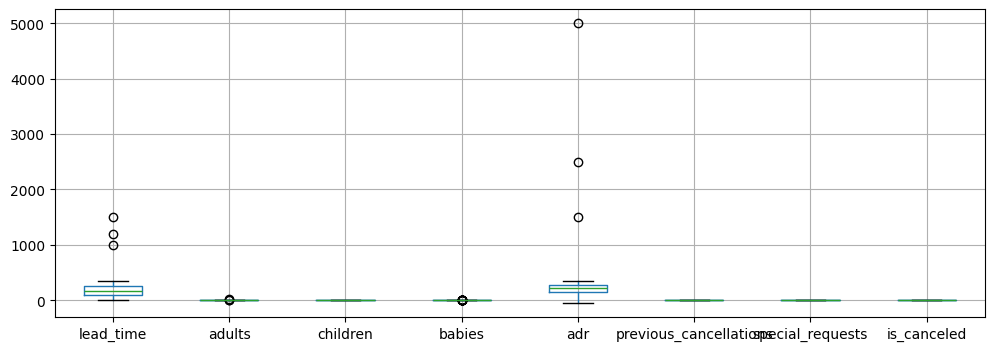

In [499]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12,4))
df2 = df.drop(columns=['lead_time', 'adr'])
df.boxplot()
#df2.boxplot()
plt.show()

In [500]:
# 결측치 처리
# children : Null 값은 0으로 대체
df["children"] = df["children"].fillna(0)
# country : Null 값은 'unknown'으로 대체
df["country"] = df["country"].fillna('unknown')
# country : Null 값은 'unknown'으로 대체
df["deposit_type"] = df["deposit_type"].fillna('unknown')
# adr : Null 값은 최빈값으로 대체
df["adr"] = df["adr"].fillna(df["adr"].mode()[0])

print(df.shape)

(457, 14)


In [501]:
# 이상치 제거
# lead_time: 0~350, adr : 50~350 벗어나는 값은 삭제
df = df[(df["lead_time"] >= 0) & (df["lead_time"] <= 350) & (df["adr"] >= 50) & (df["adr"] <= 350)]
print(df.shape)

(450, 14)


In [502]:
df.describe()

,lead_time,adults,children,babies,adr,previous_cancellations,special_requests,is_canceled
count,450.000000,450.000000,450.000000,450.000000,450.000000,450.000000,450.000000,450.000000
mean,175.293333,2.315556,0.388889,0.046667,211.808889,2.600000,2.051111,0.660000
std,98.241275,1.370376,0.668983,0.211159,84.172158,1.673852,1.383827,0.474236
min,0.000000,1.000000,0.000000,0.000000,50.000000,0.000000,0.000000,0.000000
25%,95.000000,2.000000,0.000000,0.000000,143.250000,1.000000,1.000000,0.000000
50%,175.500000,2.000000,0.000000,0.000000,225.000000,3.000000,2.000000,1.000000
75%,256.750000,3.000000,1.000000,0.000000,279.750000,4.000000,3.000000,1.000000
max,349.000000,20.000000,2.000000,1.000000,348.000000,5.000000,4.000000,1.000000


In [503]:
df["country"].unique()

array(['KOR', 'GBR', 'FRA', 'JPN', 'USA', 'CHN', 'unknown'], dtype=object)

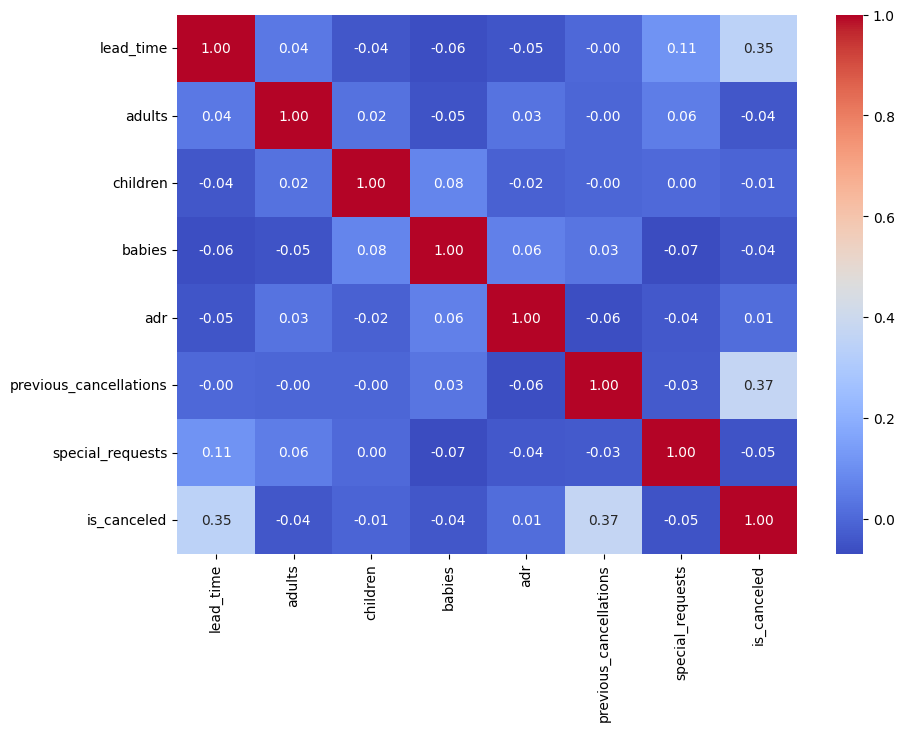

In [504]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 7))
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.show()

In [505]:
X = df.drop(columns=['is_canceled'])
y = df['is_canceled']

In [506]:
# 데이터 분리
from sklearn.model_selection import train_test_split
train_input, test_input, train_target, test_target = train_test_split(X, y, random_state = 42, test_size = 0.3, stratify = y)
print(train_input.shape, test_input.shape, train_target.shape, test_target.shape)
train_input.info()

(315, 13) (135, 13) (315,) (135,)
<class 'pandas.core.frame.DataFrame'>
Index: 315 entries, 330 to 161
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   hotel                   315 non-null    object 
 1   lead_time               315 non-null    int64  
 2   arrival_month           315 non-null    object 
 3   adults                  315 non-null    int64  
 4   children                315 non-null    float64
 5   babies                  315 non-null    int64  
 6   country                 315 non-null    object 
 7   market_segment          315 non-null    object 
 8   deposit_type            315 non-null    object 
 9   customer_type           315 non-null    object 
 10  adr                     315 non-null    float64
 11  previous_cancellations  315 non-null    int64  
 12  special_requests        315 non-null    int64  
dtypes: float64(2), int64(5), object(6)
memory usage: 34.5+ KB


In [507]:
# 특정 컬럼들만 지정해서 원 핫 인코딩 적용

# test_input에는 deposit_type 값이 unknown인 데이터가 없음! -> 아래와 같이 단순 변환하면 test_input에는 deposit_type_unknow 컬럼이 생기지 않음!!
train_input = pd.get_dummies(train_input, columns=['hotel', 'country', 'market_segment', 'deposit_type', 'customer_type'])
test_input = pd.get_dummies(test_input, columns=['hotel', 'country', 'market_segment', 'deposit_type', 'customer_type'])

# 훈련 데이터와 테스트 데이터의 컬럼을 동일하게 맞춤 (누락된 컬럼은 0으로 채움)
train_input, test_input = train_input.align(
    test_input, join="left", axis=1, fill_value=0
)
print(train_input.shape, test_input.shape)

(315, 28) (135, 28)


In [508]:
# 1. 월(Month)을 계절(Season)로 변환하는 딕셔너리 정의
season_mapping = {
    "Dec": 3,    "Jan": 3,    "Feb": 3,    "Mar": 0,    "Apr": 0,    "May": 0,
    "Jun": 1,    "Jul": 1,    "Aug": 1,    "Sep": 2,    "Oct": 2,    "Nov": 2
}

# 2. train_input과 test_input에 각각 매핑 적용
train_input["arrival_season"] = train_input["arrival_month"].map(season_mapping)
test_input["arrival_season"] = test_input["arrival_month"].map(season_mapping)

train_input = train_input.drop(columns=["arrival_month"])
test_input = test_input.drop(columns=["arrival_month"])

#print(train_input.info())
#print(test_input.info())

is_canceled               1.000000
previous_cancellations    0.383927
lead_time                 0.349798
children                  0.020938
adr                       0.015630
arrival_season           -0.012063
special_requests         -0.028562
babies                   -0.053383
adults                   -0.079524
Name: is_canceled, dtype: float64


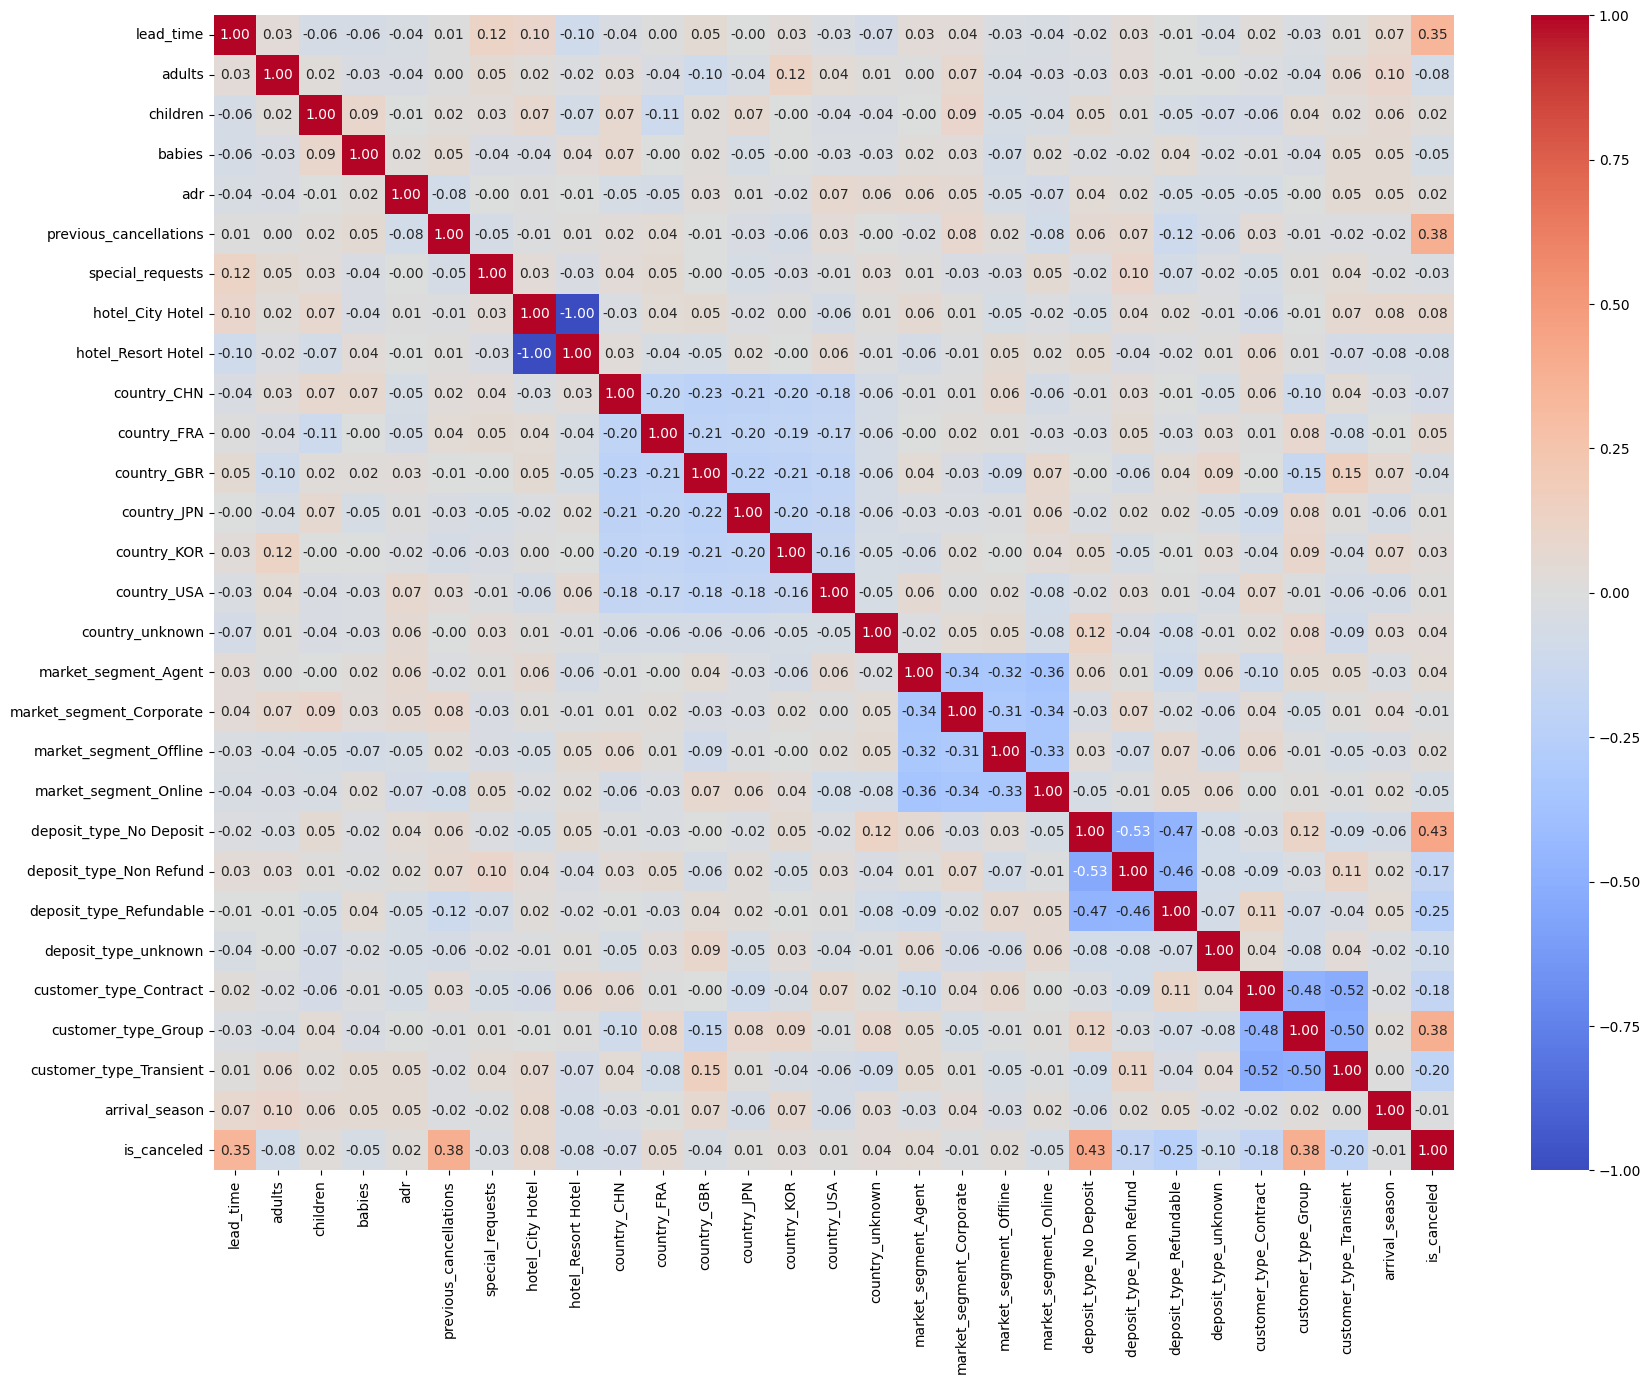

In [509]:
# 1. Train 데이터셋만 합쳐서 상관계수 확인 (수치형 컬럼 대상)
train_df = pd.concat([train_input, train_target], axis=1)
numeric_cols = train_df.select_dtypes(include=['int64', 'float64']).columns
train_corr = train_df[numeric_cols].corr()

# 2. 타깃(is_canceled)과의 상관계수 확인
print(train_corr['is_canceled'].sort_values(ascending=False))

plt.figure(figsize=(20, 15))
sns.heatmap(
    train_df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.show()

In [510]:
# 데이터 표준화
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

# 테스트 데이터로 훈련 데이터 특성이 누수되는 것을 막기 위해 훈련 데이터에만 fit()
train_scaled = scaler.fit_transform(train_input)
test_scaled = scaler.transform(test_input)

In [511]:
# LogisticRegression
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(max_iter = 1000)
lr.fit(train_scaled, train_target)
print(lr.score(train_scaled, train_target))
print(lr.score(test_scaled, test_target))

0.9301587301587302
0.8888888888888888


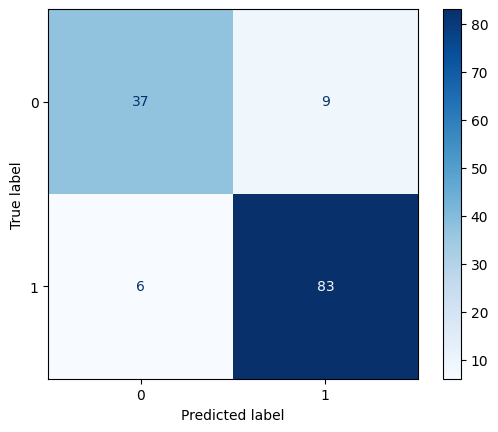

정확도 : 0.8888888888888888
정밀도 : 0.9021739130434783
재현율 : 0.9325842696629213
특이도 : 0.8043478260869565


In [512]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(
    lr,
    test_scaled, test_target,
    cmap = 'Blues'
)
plt.show()

y_pred = lr.predict(test_scaled)
cm = confusion_matrix(test_target, y_pred)
tn, fp, fn, tp = cm.ravel()

print("정확도 :", (tp+tn)/(tp+fp+fn+tn))
print("정밀도 :", tp/(tp+fp))
print("재현율 :", tp/(tp+fn))
print("특이도 :", tn/(tn+fp))

In [513]:
# KNeighborsClassifier
from sklearn.neighbors import KNeighborsClassifier
kn = KNeighborsClassifier(n_neighbors = 5)
kn.fit(train_scaled, train_target)
print(kn.score(train_scaled, train_target))
print(kn.score(test_scaled, test_target))

0.8317460317460318
0.8148148148148148


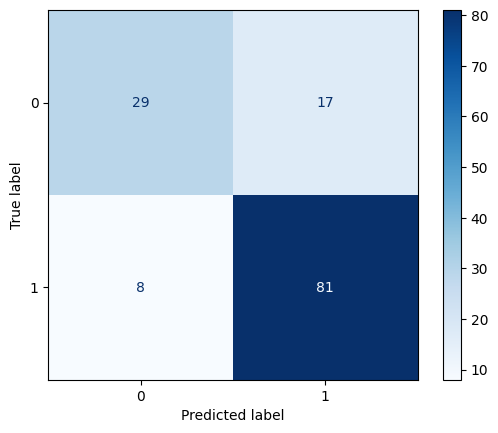

정확도 : 0.8148148148148148
정밀도 : 0.826530612244898
재현율 : 0.9101123595505618
특이도 : 0.6304347826086957


In [514]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(
    kn,
    test_scaled, test_target,
    cmap = 'Blues'
)
plt.show()

y_pred = kn.predict(test_scaled)
cm = confusion_matrix(test_target, y_pred)
tn, fp, fn, tp = cm.ravel()

print("정확도 :", (tp+tn)/(tp+fp+fn+tn))
print("정밀도 :", tp/(tp+fp))
print("재현율 :", tp/(tp+fn))
print("특이도 :", tn/(tn+fp))

In [515]:
# DecisionTreeClassifier
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(
    #max_depth = 6,
    random_state = 42
)
dt.fit(train_scaled, train_target)
print(dt.score(train_scaled, train_target))
print(dt.score(test_scaled, test_target))

1.0
0.9925925925925926


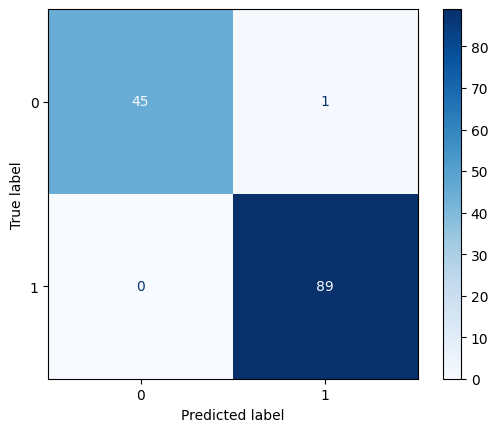

정확도 : 0.9925925925925926
정밀도 : 0.9888888888888889
재현율 : 1.0
특이도 : 0.9782608695652174


In [516]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(
    dt,
    test_scaled, test_target,
    cmap = 'Blues'
)
plt.show()

y_pred = dt.predict(test_scaled)
cm = confusion_matrix(test_target, y_pred)
tn, fp, fn, tp = cm.ravel()

print("정확도 :", (tp+tn)/(tp+fp+fn+tn))
print("정밀도 :", tp/(tp+fp))
print("재현율 :", tp/(tp+fn))
print("특이도 :", tn/(tn+fp))

In [517]:
# RandomForestClassifier
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators = 100, min_samples_split = 2, random_state = 42)
rf.fit(train_scaled, train_target)
print(rf.score(train_scaled, train_target))
print(rf.score(test_scaled, test_target))

1.0
0.9851851851851852


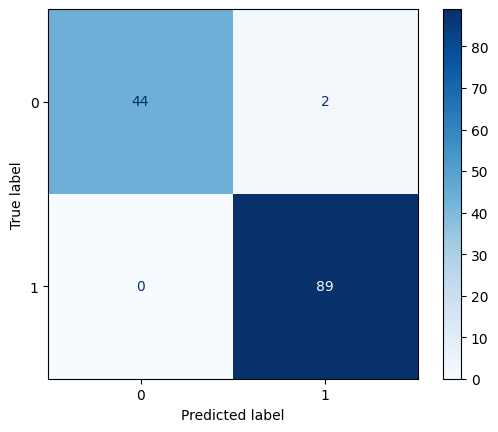

정확도 : 0.9851851851851852
정밀도 : 0.978021978021978
재현율 : 1.0
특이도 : 0.9565217391304348


In [518]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(
    rf,
    test_scaled, test_target,
    cmap = 'Blues'
)
plt.show()

y_pred = rf.predict(test_scaled)
cm = confusion_matrix(test_target, y_pred)
tn, fp, fn, tp = cm.ravel()

print("정확도 :", (tp+tn)/(tp+fp+fn+tn))
print("정밀도 :", tp/(tp+fp))
print("재현율 :", tp/(tp+fn))
print("특이도 :", tn/(tn+fp))